In [34]:
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field
import operator

In [35]:
load_dotenv()

True

In [36]:
generator_llm = ChatOpenAI(model='gpt-4o-mini')
evaluator_llm = ChatOpenAI(model='gpt-4o-mini')
optimizer_llm = ChatOpenAI(model='gpt-4o-mini')

In [37]:
class TweetEvaluation(BaseModel):

    evaluation: Literal['approved', 'needs_improvement'] = Field(..., description='Final evaluation result')
    feedback: str = Field(description='feedback for the tweet')

struc_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [38]:
class TweetState(TypedDict):

    topic: str
    tweet: str
    evaluation: Literal['approved', 'needs_improvement']
    feedback: str
    iteration: int
    max_iteration: int

    tweet_hist: Annotated[list[str], operator.add]
    feedback_hist: Annotated[list[str], operator.add]

In [39]:
def gen_tweet(state: TweetState):

    ##prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
            Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

            Rules:
            Do NOT use question-answer format.
            Max 280 characters.
            Use observational humor, irony, sarcasm, or cultural references.
            Think in meme logic, punchlines, or relatable takes.
            Use simple, day to day english
            This is version {state ['iteration'] + 1}.
        """)
    ]

    ##generate
    response = generator_llm.invoke(messages).content
    
    ##return
    return {'tweet': response, 'tweet_hist': [response]}

In [40]:
def eval_tweet(state: TweetState):

    messages = [
        SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
        HumanMessage(content=f"""
        Evaluate the following tweet:
        Tweet: "{state ['tweet']}"
        Use the criteria below to evaluate the tweet:
        1. Originality Is this fresh, or have you seen it a hundred times before?
        2. Humor Did it genuinely make you smile, laugh, or chuckle?
        3. Punchiness Is it short, sharp, and scroll-stopping?
        4. Virality Potential Would people retweet or share it?
        5. Format Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

        Auto-reject if:
        It's written in question-answer format (e.g., "Why did..." or "What happens when...")
        It exceeds 280 characters
        It reads like a traditional setup-punchline joke
        Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., "Masterpieces of the auntie-uncle universe" or vague summaries)

        ### Respond ONLY in structured format:
        evaluation: "approved" or "needs_improvement"
        feedback: One paragraph explaining the strengths and weaknesses""")
    ]

    response = struc_evaluator_llm.invoke(messages)

    return {'evaluation': response.evaluation, 'feedback': response.feedback, 'feedback_hist': [response.feedback]}


In [41]:
def opt_tweet(state: TweetState):

    messages =  [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
        Improve the tweet based on this feedback:
        "{state['feedback']}"
        Topic: "{state['topic']}"
        Original Tweet:
        {state['tweet']}
        
        Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
        """)]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_hist': [response]}

In [42]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [43]:
graph = StateGraph(TweetState)

graph.add_node('gen_tweet', gen_tweet)
graph.add_node('eval_tweet', eval_tweet)
graph.add_node('opt_tweet',  opt_tweet)

graph.add_edge(START, 'gen_tweet')
graph.add_edge('gen_tweet', 'eval_tweet')
graph.add_conditional_edges('eval_tweet', route_evaluation, {'approved': END, 'needs_improvement': 'opt_tweet'})
graph.add_edge('opt_tweet', 'eval_tweet')

workflow = graph.compile()

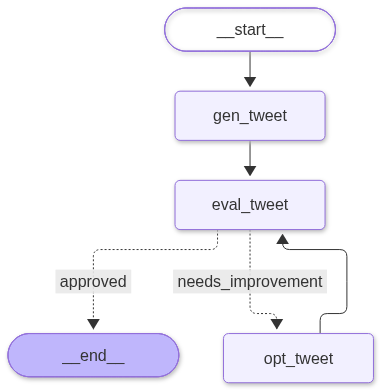

In [44]:
workflow

In [60]:
initial_state = {
    'topic': 'Indian elections and democracy in India',
    'iteration': 1,
    'max_iteration': 5
}

result = workflow.invoke(initial_state)
result

{'topic': 'Indian elections and democracy in India',
 'tweet': 'Indian elections are basically a Bollywood blockbuster: over-the-top drama, surprise cameos, and everyone’s vying for the lead role. Just a reminder—no matter who ‘wins’ the Oscar, we’re all stuck in line for the sequel! 🍿😂 #Elections2024 #DramaUnfolds',
 'evaluation': 'approved',
 'feedback': "This tweet effectively draws a humorous parallel between Indian elections and Bollywood movies, showcasing originality with a fresh perspective that hasn’t been overused. The clever imagery of 'drama' and 'surprise cameos' adds vibrancy while the punchy conclusion ties it all together without diminishing the humor. Its relatable content boosts its potential for virality, as many can resonate with the frustrations of election season. The format is well-structured, staying under the character limit while maintaining clarity and wit.",
 'iteration': 2,
 'max_iteration': 5,
 'tweet_hist': ['Indian elections are like a Bollywood movie—th

In [64]:
for tweet in result['tweet_hist']:
    print('\n', tweet)


 Indian elections are like a Bollywood movie—there’s drama, unexpected plot twists, and everyone’s fighting for the lead role. Just remember, no matter who wins, we all get to pay for the sequel! 🍿🎬 #DemocracyInAction #Elections2024

 Indian elections are basically a Bollywood blockbuster: over-the-top drama, surprise cameos, and everyone’s vying for the lead role. Just a reminder—no matter who ‘wins’ the Oscar, we’re all stuck in line for the sequel! 🍿😂 #Elections2024 #DramaUnfolds


In [65]:
for feedback in result['feedback_hist']:
    print('\n', feedback)


 While the tweet draws a clever parallel between Indian elections and Bollywood movies, the humor falls flat due to predictability and a lack of sharpness. The analogy is not entirely fresh, as many have compared elections to movies before. Although it captures a relatable sentiment, the twist about paying for the sequel feels weak and deflating rather than punchy. Furthermore, while it has some virality potential due to its topical nature, the overall execution doesn't create a compelling enough hook to encourage retweets or shares.

 This tweet effectively draws a humorous parallel between Indian elections and Bollywood movies, showcasing originality with a fresh perspective that hasn’t been overused. The clever imagery of 'drama' and 'surprise cameos' adds vibrancy while the punchy conclusion ties it all together without diminishing the humor. Its relatable content boosts its potential for virality, as many can resonate with the frustrations of election season. The format is well-s